# AML 03 — Syntactic Dependency Patterns and Causal Candidate Relation Extraction

**Project**: Neuro-Symbolic Causal Inference via Language Model Knowledge Extraction and Bayesian Networks  
**Pipeline Stage**: Classical / Symbolic NLP — Candidate Relation Mining (AML Track)  
**Upstream Dependencies**: [`00_setup.ipynb`](../00_setup.ipynb), [`AML_01_data_features.ipynb`](AML_01_data_features.ipynb), [`AML_02_ner.ipynb`](AML_02_ner.ipynb)  
**Downstream Interface**: Feeds structured in-memory candidate constraints to [`AML_05_integration_evaluation.ipynb`](AML_05_integration_evaluation.ipynb)

---

### Executive Overview

This notebook implements an end-to-end, deterministic, rule-based and syntactic dependency pattern extraction pipeline for the **Corr2Cause** benchmark (Jin et al., 2023). In the broader neuro-symbolic causal inference architecture, language models and statistical text extractors provide noisy or candidate evidence regarding variables, statistical associations, and potential causal relations. This notebook bridges linguistic surface structure and formal symbolic representations by extracting **candidate causal relationships**, **observational correlations**, and **conditional independence constraints** from natural language text.

### Critical Scope and Scientific Disclaimer

> **IMPORTANT SCIENTIFIC DISCLAIMER**:
> This notebook performs **textual candidate relation extraction** based on surface syntax, grammatical dependency trees, and formulaic linguistic patterns.
> - Extracting a textual pattern (e.g., `"A directly causes B"` or `"A correlates with B"`) **does not** prove empirical causation.
> - Candidate relations extracted from text **do not** automatically establish a valid, acyclic causal Directed Acyclic Graph (DAG) without downstream cycle-resolution and d-separation validation.
> - Candidate relations **do not** license causal intervention queries ($do(X)$) or counterfactual inferences without structural causal models and observational consistency checks.
>
> All outputs produced by this pipeline represent candidate symbolic assertions to be audited, filtered, and verified by downstream Bayesian network reasoning in `AML_05`.

---

### Notebook Structure and Contents

1. **Project Configuration, Paths, and Reproducibility**: Repository path resolution, reproducible seeds, and environment diagnostics.
2. **Input Data Discovery, Loading, and Schema Validation**: Multi-tier data ingestion supporting local exports and remote benchmark splits.
3. **Dataset Exploration and Linguistic Conventions in Corr2Cause**: Audit of closed-system declarations, statistical assertions, and hypothesis templates.
4. **Dependency-Parser Availability and Initialization**: spaCy dependency parser detection with transparent lexical/structural grammar fallback.
5. **Pattern Definitions and Extraction Functions**: Catalog of 11 candidate relation pattern families with formal schema definitions.
6. **Linguistic Pattern Coverage**: Deterministic and dependency patterns covering passive voice, negation, mediation, and ambiguity.
7. **Extraction Over Premise and Hypothesis Text**: Independent batch extraction over validation and development records without label leakage.
8. **Evaluation and Descriptive Analysis**: Quantitative coverage metrics, relation distributions, and template alignment analysis.
9. **Visualizations and Error Analysis**: Publication-quality charts visualizing pattern frequencies and extraction coverage.
10. **Descriptive Evaluation on Held-Out Test Set**: Descriptive audit of the frozen pipeline on the 1,162 held-out test records.
11. **In-Memory Result Validation and JSON Serialization Checks**: Schema completeness, offset validation, and in-memory round-trip JSON serialization.
12. **Downstream Integration Guidance for AML_05**: Interface specification and constraint-builder helpers for Bayesian network integration.
13. **Summary, Assumptions, and Limitations**: Methodological assumptions, error analysis, and pipeline takeaways.


## 1. Project Configuration, Paths, and Reproducibility

We configure repository path resolution to support execution from both the repository root (`causal-nlp-reasoning/`) and the `AML/` subdirectory. Reproducibility seeds and data path constants are established following the conventions in `AML_01` and `AML_02`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import re
import json
import copy
from pathlib import Path
from typing import Dict, List, Set, Tuple, Optional, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

def find_repo_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "00_setup.ipynb").exists() and (candidate / "data").exists():
            return candidate
        if (candidate / ".git").exists() and (candidate / "AML").exists():
            return candidate
    raise FileNotFoundError("Could not locate repository root.")

REPO_ROOT = find_repo_root()
print(f"Repository root: {REPO_ROOT.name}")


Repository root: causal-nlp-reasoning


### Path Discovery and Split Constants

In [2]:
def find_repo_root() -> Path:
    """Locate repository root directory from current working directory."""
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "00_setup.ipynb").exists() and (candidate / "data").exists():
            return candidate
        if (candidate / ".git").exists() and (candidate / "AML").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not locate repository root from '{current}'. "
        "Ensure notebook is run within 'causal-nlp-reasoning' repository tree."
    )

REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# Constants established in 00_setup and AML_01
EXPECTED_COLUMNS = ["input", "label", "num_variables", "template"]
DEV_SIZE = 1_076
TEST_SIZE = 1_162
SEED = 42

np.random.seed(SEED)

print(f"Repository root     : {REPO_ROOT.name}")
print(f"Processed data dir  : {PROCESSED_DIR.relative_to(REPO_ROOT)} [exists={PROCESSED_DIR.exists()}]")

Repository root     : causal-nlp-reasoning
Processed data dir  : data/processed [exists=True]


## 2. Input Data Discovery, Loading, and Schema Validation

We implement a transparent, verified multi-tier data discovery strategy:
1. **Tier 1A (True Local Validation Split)**: Prioritize dedicated local dev/validation files (`dev.csv`, `validation.csv`, `ner_val.csv`, `val_features.csv`) in `data/processed/` or `data/raw/` where `len(df) == DEV_SIZE` (1,076 rows).
2. **Tier 1B (Verified Filtered Combined Data)**: Never load combined training/validation files (`ner_train_val.csv`, `train_val_features.csv`, `train_val.csv`) as validation without explicitly filtering to verified validation rows using a trustworthy original split indicator (`original_split` or `split`). If no verified split column is present or if filtering does not yield exactly 1,076 rows, the loader **fails clearly** instead of silently treating combined training data as validation.
3. **Tier 2 (In-Memory Remote Benchmark Fetch)**: If local CSVs are absent, fetch the standard benchmark split directly into memory from the Hugging Face repository (`causal-nlp/corr2cause`).

> **DATA INTEGRITY AND ISOLATION RULES**:
> - All fetched datasets remain strictly in working memory; no new files or CSVs are written to disk.
> - The held-out test set (`test.csv`, 1,162 records) is **strictly isolated** from pattern design, selection, and rule tuning. Any test-set analysis in Section 10 is purely frozen and descriptive.
> - The binary classification target label (`label`) is **never used** during relation extraction, guaranteeing zero target leakage.
> - Explicit assertions enforce exact split dimensions: 1,076 records for validation and 1,162 records for test.


In [3]:
PREMISE_HYPOTHESIS_PATTERN = re.compile(
    r"^Premise:\s*(.+?)\s*\nHypothesis:\s*(.+)$",
    re.DOTALL
)

def extract_premise_hypothesis(text: str) -> Tuple[str, str]:
    """Split Corr2Cause input string into premise and hypothesis components."""
    if not isinstance(text, str) or not text.strip():
        return ("", "")
    match = PREMISE_HYPOTHESIS_PATTERN.match(text)
    if match:
        return match.group(1).strip(), match.group(2).strip()
    return text.strip(), ""

print("✓ Premise and hypothesis separator defined.")


✓ Premise and hypothesis separator defined.


### Benchmark Split Ingestion Handler
Loads validation or test partitions with verified schema and row counts.


In [4]:
def load_corr2cause_split(split_name: str = "validation") -> Tuple[pd.DataFrame, str]:
    """Load dataset split with validation filtering and multi-tier fallback into in-memory DataFrame."""
    df = None
    source_desc = ""

    if split_name in ("validation", "dev"):
        expected_size = DEV_SIZE
        pure_local_candidates = [
            RAW_DIR / "dev.csv",
            RAW_DIR / "validation.csv",
            PROCESSED_DIR / "dev.csv",
            PROCESSED_DIR / "validation.csv",
        ]
        for path in pure_local_candidates:
            if path.exists():
                candidate_df = pd.read_csv(path)
                if len(candidate_df) == expected_size:
                    df = candidate_df
                    source_desc = f"Local validation file ({path.relative_to(REPO_ROOT)})"
                    break

        if df is None:
            for path in [PROCESSED_DIR / "train_val_features.csv", PROCESSED_DIR / "train_val.csv"]:
                if path.exists():
                    candidate_df = pd.read_csv(path)
                    split_col = "original_split" if "original_split" in candidate_df.columns else ("split" if "split" in candidate_df.columns else None)
                    if split_col:
                        val_mask = candidate_df[split_col].astype(str).str.strip().str.lower() == "validation"
                        filtered_df = candidate_df[val_mask].copy()
                        if len(filtered_df) == expected_size:
                            df = filtered_df
                            source_desc = f"Local validation filtered by '{split_col}' ({path.relative_to(REPO_ROOT)})"
                            break

        if df is None:
            remote_url = "https://huggingface.co/datasets/causal-nlp/corr2cause/raw/main/validation.csv"
            df = pd.read_csv(remote_url)
            source_desc = "Hugging Face repository (validation.csv; in-memory)"

    elif split_name == "test":
        expected_size = TEST_SIZE
        for path in [RAW_DIR / "test.csv", PROCESSED_DIR / "test.csv", PROCESSED_DIR / "test_features.csv"]:
            if path.exists():
                candidate_df = pd.read_csv(path)
                if len(candidate_df) == expected_size:
                    df = candidate_df
                    source_desc = f"Local test file ({path.relative_to(REPO_ROOT)})"
                    break

        if df is None:
            remote_url = "https://huggingface.co/datasets/causal-nlp/corr2cause/raw/main/test.csv"
            df = pd.read_csv(remote_url)
            source_desc = "Hugging Face repository (test.csv; in-memory)"
    else:
        raise ValueError(f"Unknown split name: '{split_name}'")

    if len(df) != expected_size:
        raise ValueError(f"Split '{split_name}' size mismatch: expected {expected_size:,}, got {len(df):,}")

    missing_cols = set(EXPECTED_COLUMNS) - set(df.columns)
    if missing_cols:
        raise ValueError(f"Dataset missing required columns: {missing_cols}")

    if "premise" not in df.columns or "hypothesis" not in df.columns:
        parsed = df["input"].apply(extract_premise_hypothesis)
        df["premise"] = parsed.apply(lambda x: x[0])
        df["hypothesis"] = parsed.apply(lambda x: x[1])

    df = df.copy()
    if "record_id" not in df.columns:
        df["record_id"] = np.arange(len(df), dtype=int)
    df["split"] = split_name

    return df, source_desc

print("✓ Robust benchmark split loader defined.")


✓ Robust benchmark split loader defined.


### Load and Validate Benchmark Splits
Loads verified validation (1,076 rows) and test (1,162 rows) splits.

In [5]:
print("=" * 75)
print("LOADING DATASET SPLITS (Verified Validation & Frozen Test)")
print("=" * 75)
df_val, val_source = load_corr2cause_split("validation")
print(f"✓ Validation split loaded: {len(df_val):,} rows | Source: {val_source}")

df_test, test_source = load_corr2cause_split("test")
print(f"✓ Test split loaded: {len(df_test):,} rows | Source: {test_source}")

# Explicit assertions for expected validation (1,076) and test (1,162) sizes
assert len(df_val) == DEV_SIZE, f"Validation split size mismatch: expected {DEV_SIZE:,}, got {len(df_val):,}"
assert len(df_test) == TEST_SIZE, f"Test split size mismatch: expected {TEST_SIZE:,}, got {len(df_test):,}"
assert (df_val["premise"].str.len() > 0).all(), "Premise column contains empty strings in validation!"
assert (df_val["hypothesis"].str.len() > 0).all(), "Hypothesis column contains empty strings in validation!"
assert (df_test["premise"].str.len() > 0).all(), "Premise column contains empty strings in test!"
assert (df_test["hypothesis"].str.len() > 0).all(), "Hypothesis column contains empty strings in test!"
print(f"\n✓ Input schema and split size assertions verified successfully:")
print(f"  • Validation size : {len(df_val):,} rows (expected {DEV_SIZE:,})")
print(f"  • Test size       : {len(df_test):,} rows (expected {TEST_SIZE:,})")

LOADING DATASET SPLITS (Verified Validation & Frozen Test)
✓ Validation split loaded: 1,076 rows | Source: Local validation file (data/raw/validation.csv)
✓ Test split loaded: 1,162 rows | Source: Local test file (data/raw/test.csv)

✓ Input schema and split size assertions verified successfully:
  • Validation size : 1,076 rows (expected 1,076)
  • Test size       : 1,162 rows (expected 1,162)


## 3. Dataset Exploration and Linguistic Conventions in Corr2Cause

The Corr2Cause dataset has specific formulaic linguistic characteristics:

1. **Closed-System Declaration** (in premise):
   - Format: `Suppose there is a closed system of N variables, A, B, C, ...`
   - Explicitly defines the universe of causal variables (between 2 and 6 uppercase letters).
2. **Statistical and Observational Statements** (in premise):
   - Correlation: `A correlates with B.` (symmetric, non-directional).
   - Marginal Independence: `A is independent of B.` (symmetric, empty conditioning set).
   - Conditional Independence: `A and B are independent given C.` or `... given C, D and E.` (symmetric with conditioning set).
   - Note: Premises **never** assert direct causal claims; they provide observational statistical relations.
3. **Causal Hypothesis Templates** (in hypothesis):
   - `parent`: `A directly causes B.` (direct positive active causation: $A \to B$)
   - `child`: `B directly causes A.` (reverse direct active causation: $B \to A$)
   - `non-child descendant`: `A is a cause for B, but not a direct one.` (indirect causation: $A \to \dots \to B$)
   - `non-parent ancestor`: `A causes something else which causes C.` (mediation chain: $A \to M \to C$)
   - `has_confounder`: `There exists at least one confounder (i.e., common cause) of A and B.` ($A \leftarrow C \rightarrow B$)
   - `has_collider`: `There exists at least one collider (i.e., common effect) of A and B.` ($A \rightarrow C \leftarrow B$)

In [6]:
print("=" * 80)
print("CORR2CAUSE HYPOTHESIS TEMPLATE SAMPLES (Validation Split)")
print("=" * 80)

for template_name in sorted(df_val["template"].unique()):
    sample = df_val[df_val["template"] == template_name].iloc[0]
    print(f"\nTemplate: '{template_name}' (num_variables={sample['num_variables']}, label={sample['label']})")
    print(f"  Hypothesis : {sample['hypothesis']}")
    premise_preview = sample['premise'][:140] + ("..." if len(sample['premise']) > 140 else "")
    print(f"  Premise    : {premise_preview}")

print("\n" + "=" * 80)
print("DISTRIBUTION BY VARIABLE COUNT AND TEMPLATE")
print("=" * 80)
pivot_counts = pd.crosstab(df_val["num_variables"], df_val["template"])
print(pivot_counts.to_string())

CORR2CAUSE HYPOTHESIS TEMPLATE SAMPLES (Validation Split)

Template: 'child' (num_variables=2, label=0)
  Hypothesis : B directly causes A.
  Premise    : Suppose there is a closed system of 2 variables, A and B. All the statistical relations among these 2 variables are as follows: A is indepen...

Template: 'has_collider' (num_variables=2, label=0)
  Hypothesis : There exists at least one collider (i.e., common effect) of A and B.
  Premise    : Suppose there is a closed system of 2 variables, A and B. All the statistical relations among these 2 variables are as follows: A is indepen...

Template: 'has_confounder' (num_variables=2, label=0)
  Hypothesis : There exists at least one confounder (i.e., common cause) of A and B.
  Premise    : Suppose there is a closed system of 2 variables, A and B. All the statistical relations among these 2 variables are as follows: A is indepen...

Template: 'non-child descendant' (num_variables=2, label=0)
  Hypothesis : A is a cause for B, but not a 

## 4. Dependency-Parser Availability and Initialization

We evaluate whether `spaCy` and its English model (`en_core_web_sm`) are available in the local execution environment.

### Design and Fallback Architecture
- **When spaCy is available**: The pipeline utilizes spaCy's dependency parser to parse syntactic relations (`nsubj`, `dobj`, `nsubjpass`, `agent`, `neg`, `advmod`) and tags candidates with `extraction_method = 'dependency_parser'`.
- **When spaCy is unavailable**: The pipeline automatically triggers a **documented, deterministic structural and lexical grammar fallback** and tags candidates with `extraction_method = 'rule_fallback'`.
- **Transparency requirement**: Missing parser models are **never** represented as zero-valued predictions or empty failures. Both approaches produce identical structured schemas with full provenance.

To install spaCy and the dependency model when network access is available:
```bash
pip install spacy
python -m spacy download en_core_web_sm
```

In [7]:
SPACY_AVAILABLE = False
SPACY_MODEL_NAME = "en_core_web_sm"
nlp = None

try:
    import spacy
    print(f"✓ spaCy package {spacy.__version__} is installed.")
    try:
        nlp = spacy.load(SPACY_MODEL_NAME)
        SPACY_AVAILABLE = True
        print(f"✓ Loaded spaCy dependency parser model: '{SPACY_MODEL_NAME}'")
        print(f"  Active pipeline components: {nlp.pipe_names}")
    except OSError:
        print(f"⚠ spaCy model '{SPACY_MODEL_NAME}' is not downloaded.")
        print(f"  Installation command: python -m spacy download {SPACY_MODEL_NAME}")
except ImportError:
    print("⚠ spaCy is not installed in this environment.")
    print("  Installation command: pip install spacy && python -m spacy download en_core_web_sm")

if SPACY_AVAILABLE:
    EXTRACTION_METHOD_DEFAULT = "dependency_parser"
    print("\n[Mode] Active extraction mode: DEPENDENCY_PARSER (spaCy en_core_web_sm)")
else:
    EXTRACTION_METHOD_DEFAULT = "rule_fallback"
    print("\n[Mode] Active extraction mode: RULE_FALLBACK (Deterministic structural & lexical grammar)")
    print("       All candidate extractions will execute through the verified deterministic fallback.")


✓ spaCy package 3.8.16 is installed.
✓ Loaded spaCy dependency parser model: 'en_core_web_sm'
  Active pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']

[Mode] Active extraction mode: DEPENDENCY_PARSER (spaCy en_core_web_sm)


## 5. Candidate Relation Schema and Pattern Definitions

### Output Schema Specification
Every candidate relation extracted by the pipeline adheres to the following unified schema:

| Field Name | Type | Description |
|:---|:---|:---|
| `record_id` | `int` | Stable identifier linking the candidate to its source dataset row. |
| `text_component` | `str` | Component from which candidate was mined: `'premise'` or `'hypothesis'`. |
| `cause` | `str` \| `None` | Candidate cause variable (e.g. `'A'`), or `None` if undirected/common relation. |
| `effect` | `str` \| `None` | Candidate effect variable (e.g. `'B'`), or `None` if undirected/common relation. |
| `relation_type` | `str` | Standardized relation category (see catalog below). |
| `pattern_name` | `str` | Specific grammatical or template pattern identifier. |
| `extraction_method` | `str` | `'dependency_parser'` or `'rule_fallback'`. |
| `evidence_text` | `str` | Exact textual substring providing evidence for the extraction. |
| `start_char` | `int` | Start character index in the parent text component. |
| `end_char` | `int` | End character index in the parent text component. |
| `is_negated` | `bool` | `True` if statement explicitly negates causation or association. |
| `match_metadata` | `dict` | Context metadata (variables involved, conditioning set, rule score, voice). |

### Candidate Pattern Catalog (11 Supported Families)

1. `active_direct_causal`: Active direct assertion (`"A directly causes B"`, `"A causes B"`). Direction: $A \to B$.
2. `passive_direct_causal`: Passive direct assertion (`"B is caused by A"`, `"B is directly caused by A"`). Direction: $A \to B$ (swaps syntactic subject to effect and agent object to cause).
3. `indirect_cause_not_direct`: Indirect causation (`"A is a cause for B, but not a direct one"`). Direction: $A \to B$.
4. `mediation_chain`: Causal mediation chain (`"A causes something else which causes B"`). Direction: $A \to B$ (with mediation flag).
5. `confounder_common_cause`: Common cause assertion (`"... confounder of A and B"`). Non-directional association with latent common cause.
6. `collider_common_effect`: Common effect assertion (`"... collider of A and B"`). Non-directional association with latent common collider.
7. `active_negated_causal`: Active negated causation (`"A does not cause B"`). Direction: $A \not\to B$, `is_negated=True`.
8. `passive_negated_causal`: Passive negated causation (`"B is not caused by A"`). Direction: $A \not\to B$, `is_negated=True`.
9. `correlation_statement`: Statistical correlation (`"A correlates with B"`). Symmetric association, non-directional.
10. `conditional_independence_statement`: Conditional independence (`"A and B are independent given C..."`). Symmetric, conditioning set recorded.
11. `marginal_independence_statement`: Marginal independence (`"A is independent of B"`). Symmetric, empty conditioning set.
12. `ambiguous_causal_association`: Unspecified causal link (`"There is a causal link between A and B"`). Flagged as ambiguous; direction abstained.

In [8]:
# -----------------------------------------------------------------------------
# Symbolic Entity Extraction & Source Offset Alignment Helpers
# -----------------------------------------------------------------------------
_DECL_RE = re.compile(
    r"(?i:closed system of \d+ variables,?\s+)([A-Z](?:,\s*[A-Z])*(?:,?\s+(?:and|or)\s+[A-Z])?)\.?"
)
_SINGLE_VAR_RE = re.compile(r"\b([A-Z])\b")

_ARTICLE_FOLLOW_RE = re.compile(
    r"^\s+(?:closed|collider|confounder|mediator|parent|child|direct|common|"
    r"variable|variables|system|statistical|relation|relationship|descendant|ancestor|"
    r"node|nodes|graph|graphs|path|paths|dag|dags|sentence|sentences|statement|statements|sample|samples|example|examples|case|cases)\b",
    re.IGNORECASE,
)
_ARTICLE_CAUSE_OF_RE = re.compile(
    r"^\s+cause\s+(?:of|for|between|in)\b",
    re.IGNORECASE,
)

def _is_article_a_dep(text, match):
    start = match.start()
    end = match.end()
    before = text[:start]
    after = text[end:]

    if not after or re.match(r"^\s*[,.:;?!)\]}\'\"\-\/]", after) or re.match(r"^\s*$", after):
        return False

    if _ARTICLE_FOLLOW_RE.match(after) or _ARTICLE_CAUSE_OF_RE.match(after):
        if re.search(r"\b(?:between|of|with|given|for|from|to|and|or|variable|node)\s+$", before, re.IGNORECASE):
            return False
        return True

    return False

def extract_declared_variables(text: str) -> Set[str]:
    """Extract declared symbolic variables from a premise closed-system declaration."""
    if not isinstance(text, str):
        return set()
    decl_match = _DECL_RE.search(text)
    if decl_match:
        return set(re.findall(r"\b([A-Z])\b", decl_match.group(1)))
    # Fallback: find all single capital letters with occurrence-level article disambiguation
    found = set()
    for m in _SINGLE_VAR_RE.finditer(text):
        v = m.group(1)
        if v == "I":
            continue
        if v == "A" and _is_article_a_dep(text, m):
            continue
        found.add(v)
    return found

def map_normalized_span_to_source(source_text: str, norm_start: int, norm_end: int) -> Tuple[int, int]:
    """Explicitly map character span from normalized text back to original source text offsets.
    Handles arbitrary whitespace collapsing and stripping while preserving exact source boundaries.
    """
    if not isinstance(source_text, str) or norm_start < 0 or norm_end <= norm_start:
        return -1, -1

    source_spans = []
    i = 0
    n = len(source_text)
    while i < n and source_text[i].isspace():
        i += 1
    while i < n:
        if source_text[i].isspace():
            ws_start = i
            while i < n and source_text[i].isspace():
                i += 1
            if i < n:
                source_spans.append((ws_start, i))
        else:
            source_spans.append((i, i + 1))
            i += 1

    if not source_spans or norm_start >= len(source_spans):
        return -1, -1

    start_src = source_spans[norm_start][0]
    end_norm_idx = min(norm_end - 1, len(source_spans) - 1)
    end_src = source_spans[end_norm_idx][1]
    return start_src, end_src

print("✓ Variable declaration parser and source offset alignment mapper defined.")

✓ Variable declaration parser and source offset alignment mapper defined.


### Candidate Relation Extractor
Hybrid extraction combining spaCy dependency tree traversal and verified structural/lexical grammar patterns.

In [9]:
def _extract_spacy_causal_relations(doc, source_text, record_id, text_component, allowed_vars=None):
    """Extract causal relations using spaCy dependency parse trees with exact phrase evidence spans."""
    candidates = []

    def get_var_from_tok(tok):
        v = tok.text.rstrip(".,;:?!")
        if v.isupper() and len(v) == 1:
            return v, tok.idx + len(v)
        return None, None

    for token in doc:
        if token.lemma_ == "cause" or token.text.lower() in ("causes", "caused", "cause"):
            is_neg = any(child.dep_ == "neg" for child in token.children)
            is_passive = any(child.dep_ in ("auxpass", "passive:aux") for child in token.children)

            if is_passive:
                effects = []
                for child in token.children:
                    if child.dep_ in ("nsubjpass", "nsubj"):
                        v, end_pos = get_var_from_tok(child)
                        if v:
                            effects.append((child, v))

                causes = []
                agents = [child for child in token.children if child.dep_ in ("agent", "prep") and child.lemma_ == "by"]
                for ag in agents:
                    for p in ag.children:
                        if p.dep_ in ("pobj", "obj"):
                            v, end_pos = get_var_from_tok(p)
                            if v:
                                causes.append((p, v, ag))

                if causes and effects:
                    e_tok, e_var = effects[0]
                    c_tok, c_var, ag_tok = causes[0]

                    if allowed_vars is not None and (c_var not in allowed_vars or e_var not in allowed_vars):
                        continue

                    # Exact relation phrase bounded by participating variables
                    start_char = min(e_tok.idx, c_tok.idx)
                    end_char = max(
                        e_tok.idx + len(e_tok.text.rstrip(".,;:?!")),
                        c_tok.idx + len(c_tok.text.rstrip(".,;:?!"))
                    )

                    if not (0 <= start_char < end_char <= len(source_text)):
                        continue

                    ev_text = source_text[start_char:end_char]
                    candidates.append({
                        "record_id": record_id, "text_component": text_component, "cause": c_var, "effect": e_var,
                        "relation_type": "negated_causal" if is_neg else "direct_causal",
                        "pattern_name": "passive_negated_causal" if is_neg else "passive_direct_causal",
                        "extraction_method": "dependency_parser", "evidence_text": ev_text,
                        "start_char": start_char, "end_char": end_char, "is_negated": is_neg,
                        "match_metadata": {"passive": True, "rule_score": 1.0, "variables": [c_var, e_var]}
                    })
                    continue

            # Active voice
            nsubjs = []
            for child in token.children:
                if child.dep_ in ("nsubj", "nsubjpass") or (child.dep_ == "det" and child.text.rstrip(".,;:?!") in ("A", "B", "C", "D", "E")):
                    v, end_pos = get_var_from_tok(child)
                    if v:
                        nsubjs.append((child, v))

            dobjs = []
            for child in token.children:
                if child.dep_ in ("dobj", "obj"):
                    v, end_pos = get_var_from_tok(child)
                    if v:
                        dobjs.append((child, v))

            if nsubjs and dobjs:
                c_tok, c_var = nsubjs[0]
                e_tok, e_var = dobjs[0]

                if allowed_vars is not None and (c_var not in allowed_vars or e_var not in allowed_vars):
                    continue

                # Exact relation phrase bounded by subject cause and object effect
                start_char = min(c_tok.idx, e_tok.idx)
                end_char = max(
                    c_tok.idx + len(c_tok.text.rstrip(".,;:?!")),
                    e_tok.idx + len(e_tok.text.rstrip(".,;:?!"))
                )

                if not (0 <= start_char < end_char <= len(source_text)):
                    continue

                ev_text = source_text[start_char:end_char]
                candidates.append({
                    "record_id": record_id, "text_component": text_component, "cause": c_var, "effect": e_var,
                    "relation_type": "negated_causal" if is_neg else "direct_causal",
                    "pattern_name": "active_negated_causal" if is_neg else "active_direct_causal",
                    "extraction_method": "dependency_parser", "evidence_text": ev_text,
                    "start_char": start_char, "end_char": end_char, "is_negated": is_neg,
                    "match_metadata": {"passive": False, "rule_score": 1.0, "variables": [c_var, e_var]}
                })

    return candidates

In [10]:
def _extract_rule_causal_relations(source_text, record_id, text_component, method, allowed_vars=None):
    """Extract direct and indirect causal candidate relations using deterministic patterns on source_text."""
    candidates = []

    # 1. Passive negated causation: 'B is not (directly) caused by A'
    for m in re.finditer(r"\b([A-Z])\s+is\s+not\s+(?:directly\s+)?caused\s+by\s+([A-Z])\b", source_text):
        e, c = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "negated_causal", "pattern_name": "passive_negated_causal",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": True,
            "match_metadata": {"passive": True, "rule_score": 1.0, "variables": [c, e]}
        })

    # 2. Passive direct causation: 'B is (directly) caused by A'
    for m in re.finditer(r"\b([A-Z])\s+is\s+(?:directly\s+)?caused\s+by\s+([A-Z])\b", source_text):
        if any(c["start_char"] <= m.start() and c["end_char"] >= m.end() for c in candidates):
            continue
        e, c = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "direct_causal", "pattern_name": "passive_direct_causal",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"passive": True, "rule_score": 1.0, "variables": [c, e]}
        })

    # 3. Active negated causation: 'A does not (directly) cause B'
    for m in re.finditer(r"\b([A-Z])\s+(?:does\s+not|doesn't|cannot)\s+(?:directly\s+)?cause\s+([A-Z])\b", source_text):
        c, e = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "negated_causal", "pattern_name": "active_negated_causal",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": True,
            "match_metadata": {"passive": False, "rule_score": 1.0, "variables": [c, e]}
        })

    # 4. Indirect causation (not direct one)
    for m in re.finditer(r"\b([A-Z])\s+is\s+a\s+cause\s+(?:for|of)\s+([A-Z]),?\s+but\s+not\s+a\s+direct\s+one\b", source_text):
        c, e = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "indirect_causal", "pattern_name": "indirect_cause_not_direct",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"direct": False, "rule_score": 1.0, "variables": [c, e]}
        })

    # 5. Mediation chain (causes something else which causes)
    for m in re.finditer(r"\b([A-Z])\s+causes\s+(?:something\s+else|another\s+variable|an\s+intermediate\s+variable)\s+which\s+causes\s+([A-Z])\b", source_text):
        c, e = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "indirect_causal", "pattern_name": "mediation_chain",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"mediation": True, "rule_score": 1.0, "variables": [c, e]}
        })

    # 6. Active direct causation: 'A (directly) causes B'
    for m in re.finditer(r"\b([A-Z])\s+(?:directly\s+)?causes?\s+([A-Z])\b", source_text):
        if any(c["start_char"] <= m.start() and c["end_char"] >= m.end() for c in candidates):
            continue
        c, e = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "direct_causal", "pattern_name": "active_direct_causal",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"passive": False, "rule_score": 1.0, "variables": [c, e]}
        })

    # 7. Active direct causation (noun phrase): 'A is a (direct) cause of/for B'
    for m in re.finditer(r"\b([A-Z])\s+is\s+a\s+(?:direct\s+)?cause\s+(?:of|for)\s+([A-Z])\b(?!\s*,?\s*but\s+not\s+a\s+direct\s+one\b)", source_text, re.IGNORECASE):
        if any(c["start_char"] <= m.start() and c["end_char"] >= m.end() for c in candidates):
            continue
        c, e = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "direct_causal", "pattern_name": "direct_cause_noun",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"passive": False, "rule_score": 1.0, "variables": [c, e]}
        })

    # 8. Active negated causation (noun phrase): 'A is not a (direct) cause of/for B'
    for m in re.finditer(r"\b([A-Z])\s+is\s+not\s+a\s+(?:direct\s+)?cause\s+(?:of|for)\s+([A-Z])\b", source_text, re.IGNORECASE):
        if any(c["start_char"] <= m.start() and c["end_char"] >= m.end() for c in candidates):
            continue
        c, e = m.group(1), m.group(2)
        if allowed_vars is not None and (c not in allowed_vars or e not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": c, "effect": e,
            "relation_type": "negated_causal", "pattern_name": "active_negated_causal",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": True,
            "match_metadata": {"passive": False, "rule_score": 1.0, "variables": [c, e]}
        })

    return candidates

In [11]:
def _extract_rule_statistical_relations(source_text, record_id, text_component, method, allowed_vars=None):
    """Extract statistical, associational, confounder, and collider candidate relations directly on source_text."""
    candidates = []

    # 7. Confounder: 'common cause / confounder of A and B'
    for m in re.finditer(r"(?:confounder|common\s+cause)(?:\s*\([^)]*\))?\s+of\s+([A-Z])\s+and\s+([A-Z])\b", source_text, re.IGNORECASE):
        v1, v2 = m.group(1), m.group(2)
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "common_cause", "pattern_name": "confounder_common_cause",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "rule_score": 1.0}
        })

    # 8. Collider: 'common effect / collider of A and B'
    for m in re.finditer(r"(?:collider|common\s+effect)(?:\s*\([^)]*\))?\s+of\s+([A-Z])\s+and\s+([A-Z])\b", source_text, re.IGNORECASE):
        v1, v2 = m.group(1), m.group(2)
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "common_effect", "pattern_name": "collider_common_effect",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "rule_score": 1.0}
        })

    # 9. Correlation: 'A correlates with B' or 'A and B are correlated'
    for m in re.finditer(r"\b([A-Z])\s+correlates\s+with\s+([A-Z])\b", source_text):
        v1, v2 = m.group(1), m.group(2)
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "correlation", "pattern_name": "correlation_statement",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "rule_score": 1.0}
        })

    for m in re.finditer(r"\b([A-Z])\s+and\s+([A-Z])\s+are\s+correlated\b", source_text):
        v1, v2 = m.group(1), m.group(2)
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "correlation", "pattern_name": "correlation_statement",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "rule_score": 1.0}
        })

    # 10. Conditional Independence
    for m in re.finditer(r"\b([A-Z])\s+and\s+([A-Z])\s+are\s+independent\s*,?\s*given\s+([A-Z](?:,\s*[A-Z])*(?:,?\s+and\s+[A-Z])?)\b", source_text):
        v1, v2 = m.group(1), m.group(2)
        cond_vars = re.findall(r"\b[A-Z]\b", m.group(3))
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars or any(cv not in allowed_vars for cv in cond_vars)):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "conditional_independence", "pattern_name": "conditional_independence_statement",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "conditioning_set": sorted(cond_vars), "rule_score": 1.0}
        })

    for m in re.finditer(r"\b([A-Z])\s+is\s+independent\s+of\s+([A-Z])\s*,?\s*given\s+([A-Z](?:,\s*[A-Z])*(?:,?\s+and\s+[A-Z])?)\b", source_text):
        v1, v2 = m.group(1), m.group(2)
        cond_vars = re.findall(r"\b[A-Z]\b", m.group(3))
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars or any(cv not in allowed_vars for cv in cond_vars)):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "conditional_independence", "pattern_name": "conditional_independence_statement",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "conditioning_set": sorted(cond_vars), "rule_score": 1.0}
        })

    # 11. Marginal Independence (not given)
    for m in re.finditer(r"\b([A-Z])\s+is\s+independent\s+of\s+([A-Z])\b(?!\s*,?\s*given\b)", source_text):
        v1, v2 = m.group(1), m.group(2)
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "independence", "pattern_name": "marginal_independence_statement",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "conditioning_set": [], "rule_score": 1.0}
        })

    for m in re.finditer(r"\b([A-Z])\s+and\s+([A-Z])\s+are\s+independent\b(?!\s*,?\s*given\b)", source_text):
        v1, v2 = m.group(1), m.group(2)
        if allowed_vars is not None and (v1 not in allowed_vars or v2 not in allowed_vars):
            continue
        candidates.append({
            "record_id": record_id, "text_component": text_component, "cause": None, "effect": None,
            "relation_type": "independence", "pattern_name": "marginal_independence_statement",
            "extraction_method": method, "evidence_text": m.group(0),
            "start_char": m.start(), "end_char": m.end(), "is_negated": False,
            "match_metadata": {"variables": sorted([v1, v2]), "conditioning_set": [], "rule_score": 1.0}
        })

    return candidates

In [12]:
def extract_candidate_relations(
    text: str,
    text_component: str = "hypothesis",
    record_id: int = 0,
    method: Optional[str] = None,
    allowed_vars: Optional[Set[str]] = None
) -> List[Dict[str, Any]]:
    """Extract structured candidate causal and statistical relations from text with exact phrase evidence spans.
    Preserves exact source offsets without destructive stripping or normalization drift.

    Hybrid Parser & Rule Recovery Architecture:
    - If method == dependency_parser and spaCy is available, extracts primary causal candidates via dependency parse.
    - Rule-based causal and statistical grammars are also consulted to recover valid candidate relations missed by
      the dependency parser (e.g. secondary causal clauses, indirect causal phrasing, and statistical relations).
    - Candidates that duplicate a parser candidate (matching relation_type, cause, effect, and overlapping span) are
      deduplicated, strictly preserving parser provenance for parser-extracted relations.
    - If method != dependency_parser or spaCy is unavailable, rule grammar executes deterministically.
    """
    if method is None:
        method = EXTRACTION_METHOD_DEFAULT

    if not isinstance(text, str) or not text.strip():
        return []

    source_text = text
    parser_candidates = []

    # Branch A: spaCy Dependency Parser (if available and requested)
    if method == "dependency_parser" and SPACY_AVAILABLE and nlp is not None:
        doc = nlp(source_text)
        parser_candidates = _extract_spacy_causal_relations(
            doc, source_text, record_id, text_component, allowed_vars
        )

    # Branch B: Deterministic Structural & Lexical Grammar Fallback / Recovery
    fallback_method = "rule_fallback" if method == "dependency_parser" else method
    rule_causal = _extract_rule_causal_relations(
        source_text, record_id, text_component, fallback_method, allowed_vars
    )
    rule_statistical = _extract_rule_statistical_relations(
        source_text, record_id, text_component, fallback_method, allowed_vars
    )

    combined = list(parser_candidates)

    # Recover rule causal candidates that are not already covered by parser candidates
    for r in rule_causal:
        is_covered = False
        for p in parser_candidates:
            if (
                p["relation_type"] == r["relation_type"]
                and p.get("cause") == r.get("cause")
                and p.get("effect") == r.get("effect")
                and max(p["start_char"], r["start_char"]) < min(p["end_char"], r["end_char"])
            ):
                is_covered = True
                break
        if not is_covered:
            combined.append(r)

    # Statistical relations are not handled by dependency parser; include all valid rule statistical relations
    combined.extend(rule_statistical)

    # Deduplicate candidates matching identical signatures and validate exact spans
    unique_candidates = []
    seen_signatures = set()
    for c in combined:
        meta_vars = tuple(sorted(c.get("match_metadata", {}).get("variables", [])))
        cond_vars = tuple(sorted(c.get("match_metadata", {}).get("conditioning_set", [])))
        sig = (c["relation_type"], c.get("cause"), c.get("effect"), meta_vars, cond_vars, c["start_char"], c["end_char"])
        if sig not in seen_signatures:
            seen_signatures.add(sig)
            assert source_text[c["start_char"]:c["end_char"]] == c["evidence_text"], (
                f"Span offset mismatch: expected '{c['evidence_text']}', found '{source_text[c['start_char']:c['end_char']]}'"
            )
            assert 0 <= c["start_char"] < c["end_char"] <= len(source_text), (
                f"Invalid offset bounds: start={c['start_char']}, end={c['end_char']}, len={len(source_text)}"
            )
            unique_candidates.append(c)

    return unique_candidates

print("✓ Modular hybrid candidate relation extraction engine defined.")

✓ Modular hybrid candidate relation extraction engine defined.


### Causal Constraint Translation for Bayesian Network Inference
Translates candidate relations into directed edges, directed ancestral paths, exclusions, and independence sets.

In [13]:
def _parse_premise_constraints(premise_candidates):
    """Extract observational correlations and independencies from premise candidates."""
    correlations, conditional_independencies, marginal_independencies = [], [], []
    for c in premise_candidates:
        rtype = c["relation_type"]
        vars_involved = c["match_metadata"].get("variables", [])
        if rtype == "correlation" and len(vars_involved) == 2:
            correlations.append(tuple(vars_involved))
        elif rtype == "conditional_independence" and len(vars_involved) == 2:
            cond_set = tuple(c["match_metadata"].get("conditioning_set", []))
            conditional_independencies.append((vars_involved[0], vars_involved[1], cond_set))
        elif rtype == "independence" and len(vars_involved) == 2:
            marginal_independencies.append(tuple(vars_involved))
    return correlations, conditional_independencies, marginal_independencies

def _parse_hypothesis_constraints(hypothesis_candidates):
    """Extract causal graph edge requirements and restrictions from hypothesis candidates."""
    directed_edges, directed_paths, forbidden_edges = [], [], []
    common_causes, common_effects = [], []

    for c in hypothesis_candidates:
        rtype = c["relation_type"]
        cause, effect = c.get("cause"), c.get("effect")
        vars_involved = c["match_metadata"].get("variables", [])

        if rtype == "direct_causal" and cause and effect:
            if c["is_negated"]:
                forbidden_edges.append((cause, effect))
            else:
                directed_edges.append((cause, effect))
        elif rtype == "indirect_causal" and cause and effect:
            if not c["is_negated"]:
                directed_paths.append((cause, effect))
                forbidden_edges.append((cause, effect))
        elif rtype == "negated_causal" and cause and effect:
            forbidden_edges.append((cause, effect))
        elif rtype == "common_cause" and len(vars_involved) == 2:
            common_causes.append(tuple(vars_involved))
        elif rtype == "common_effect" and len(vars_involved) == 2:
            common_effects.append(tuple(vars_involved))

    return directed_edges, directed_paths, forbidden_edges, common_causes, common_effects


In [14]:
def get_record_causal_constraints(record_dict: Dict[str, Any]) -> Dict[str, Any]:
    """Translate an in-memory candidate relation record into structured Bayesian network constraints."""
    correlations, cond_indeps, marg_indeps = _parse_premise_constraints(record_dict.get("premise_candidates", []))
    dir_edges, dir_paths, forb_edges, com_causes, com_effects = _parse_hypothesis_constraints(record_dict.get("hypothesis_candidates", []))

    return {
        "record_id": record_dict.get("record_id", 0),
        "template": record_dict.get("template", ""),
        "declared_variables": record_dict.get("declared_variables", []),
        "directed_edges": sorted(list(set(dir_edges))),
        "directed_paths": sorted(list(set(dir_paths))),
        "indirect_causal_paths": sorted(list(set(dir_paths))),
        "forbidden_edges": sorted(list(set(forb_edges))),
        "undirected_correlations": sorted(list(set(correlations))),
        "conditional_independencies": sorted(list(set(cond_indeps))),
        "marginal_independencies": sorted(list(set(marg_indeps))),
        "common_causes": sorted(list(set(com_causes))),
        "common_effects": sorted(list(set(com_effects))),
    }

print("✓ Structured Bayesian DAG constraint builder defined.")


✓ Structured Bayesian DAG constraint builder defined.


## 6. Extraction Over Premise and Hypothesis Text (Validation Split)

We execute the candidate relation extraction pipeline over the development/validation split (`df_val`, 1,076 records).

### Methodological Safeguards
- **Independent Component Processing**: Premise and hypothesis are extracted separately via distinct function calls.
- **Stable Alignment**: Each candidate preserves the original integer `record_id`, allowing lossless re-aggregation.
- **Provenance Tracking**: Every candidate records its source component (`'premise'` or `'hypothesis'`), extraction method, and exact character boundaries.


In [15]:
def process_dataset_records(df: pd.DataFrame, split_name: str = "validation") -> Tuple[List[Dict[str, Any]], pd.DataFrame]:
    """Process DataFrame rows and return in-memory structured records and flattened candidate DataFrame."""
    structured_records = []
    flattened_candidates = []

    for _, row in df.iterrows():
        rec_id = int(row["record_id"])
        prem_text = row["premise"]
        hyp_text = row["hypothesis"]
        num_vars = int(row["num_variables"])
        template = str(row["template"])
        declared_vars = extract_declared_variables(prem_text)

        # 1. Extract candidates from premise
        prem_candidates = extract_candidate_relations(
            prem_text,
            text_component="premise",
            record_id=rec_id,
            allowed_vars=declared_vars
        )

        # 2. Extract candidates from hypothesis
        hyp_candidates = extract_candidate_relations(
            hyp_text,
            text_component="hypothesis",
            record_id=rec_id,
            allowed_vars=declared_vars
        )

        # 3. Assemble record
        rec_entry = {
            "record_id": rec_id,
            "split": split_name,
            "num_variables": num_vars,
            "template": template,
            "declared_variables": sorted(list(declared_vars)),
            "premise_text": prem_text,
            "hypothesis_text": hyp_text,
            "premise_candidates": prem_candidates,
            "hypothesis_candidates": hyp_candidates,
            "premise_candidate_count": len(prem_candidates),
            "hypothesis_candidate_count": len(hyp_candidates),
            "has_causal_hypothesis": any(c["relation_type"] in ("direct_causal", "indirect_causal") for c in hyp_candidates),
        }
        structured_records.append(rec_entry)

        # Flatten for tabular analysis
        for c in prem_candidates + hyp_candidates:
            c_row = copy.deepcopy(c)
            c_row["split"] = split_name
            c_row["num_variables"] = num_vars
            c_row["template"] = template
            flattened_candidates.append(c_row)

    df_candidates = pd.DataFrame(flattened_candidates)
    return structured_records, df_candidates

print("✓ Dataset record processor defined.")

✓ Dataset record processor defined.


### Execute Extraction on Validation Split
Extracts observational premise constraints and hypothesis causal queries across 1,076 validation records.

In [16]:
print(f"Processing {len(df_val):,} validation split records...")
val_records, df_val_candidates = process_dataset_records(df_val, split_name="validation")

print(f"Extracted candidate relations across validation records.")
print(f"  Records processed            : {len(val_records):,}")
print(f"  Total candidate relations     : {len(df_val_candidates):,}")
print(f"  Premise candidate relations   : {(df_val_candidates['text_component'] == 'premise').sum():,}")
print(f"  Hypothesis candidate relations: {(df_val_candidates['text_component'] == 'hypothesis').sum():,}")

Processing 1,076 validation split records...


Extracted candidate relations across validation records.
  Records processed            : 1,076
  Total candidate relations     : 37,872
  Premise candidate relations   : 36,796
  Hypothesis candidate relations: 1,076


## 7. Evaluation and Descriptive Analysis

We evaluate the extraction pipeline using clear, mathematically well-defined descriptive metrics, strictly distinguishing between **record coverage** and **relation-level extraction correctness**.

### Defined Metrics and Diagnostic Distinctions
1. **Record Extraction Coverage** (Diagnostic Breadth):
   $$\text{Coverage}_{\text{record}} = \frac{\text{Records with } \ge 1 \text{ candidate relation}}{\text{Total records evaluated}}$$
   *Important Methodological Distinction*: Record coverage measures whether the syntactic and regex grammar matched at least one surface relation in a given record. **100% record coverage does not mean 100% extraction accuracy.** It does not guarantee that every ground-truth causal relation in the premise was mined, nor that extracted candidates are empirically valid.
2. **Premise Component Coverage**:
   $$\text{Coverage}_{\text{premise}} = \frac{\text{Records with } \ge 1 \text{ premise candidate}}{\text{Total records evaluated}}$$
3. **Hypothesis Component Coverage**:
   $$\text{Coverage}_{\text{hypothesis}} = \frac{\text{Records with } \ge 1 \text{ hypothesis candidate}}{\text{Total records evaluated}}$$
4. **Hypothesis Template Alignment** (Diagnostic Sanity Check):
   - Evaluates whether extracted hypothesis relations align with the semantic category of the Corr2Cause template:
     - `parent` & `child` $\to$ `direct_causal`
     - `non-child descendant` & `non-parent ancestor` $\to$ `indirect_causal`
     - `has_confounder` $\to$ `common_cause`
     - `has_collider` $\to$ `common_effect`
   *Diagnostic Limitations*: Template alignment verifies that the formulaic hypothesis template was categorized as intended; it is a sanity check on hypothesis routing, not a proof of premise relation precision, d-separation consistency, or causal DAG correctness.
5. **Variable Consistency with Closed-System Declarations**:
   - Verifies that all variables extracted in candidate relations are members of the declared variable universe in the premise.
   - Performed via a strictly non-mutating audit preserving original candidate records.


In [17]:
n_total = len(val_records)
n_with_any = sum(1 for r in val_records if r["premise_candidate_count"] + r["hypothesis_candidate_count"] > 0)
n_with_prem = sum(1 for r in val_records if r["premise_candidate_count"] > 0)
n_with_hyp = sum(1 for r in val_records if r["hypothesis_candidate_count"] > 0)

print("=" * 75)
print("EXTRACTION RECORD COVERAGE (Diagnostic Metric — Validation Split)")
print("=" * 75)
print(f"Total records evaluated         : {n_total:,}")
print(f"Overall record coverage         : {n_with_any:,} / {n_total:,} ({n_with_any / n_total:6.2%})")
print(f"Premise component coverage      : {n_with_prem:,} / {n_total:,} ({n_with_prem / n_total:6.2%})")
print(f"Hypothesis component coverage   : {n_with_hyp:,} / {n_total:,} ({n_with_hyp / n_total:6.2%})")
print("\n[Methodological Note: 100% record coverage indicates every record yielded at least")
print(" one candidate relation. Record coverage measures grammar breadth; it must NOT be")
print(" conflated with relation-level precision/recall or ground-truth causal validity.]")

# Verification of template alignment
hyp_cands = df_val_candidates[df_val_candidates["text_component"] == "hypothesis"]
hyp_matrix = pd.crosstab(hyp_cands["template"], hyp_cands["relation_type"])
template_alignment_correct = 0
for _, row in hyp_cands.iterrows():
    tmpl = row["template"]
    rel = row["relation_type"]
    if tmpl in ("parent", "child") and rel == "direct_causal":
        template_alignment_correct += 1
    elif tmpl in ("non-child descendant", "non-parent ancestor") and rel == "indirect_causal":
        template_alignment_correct += 1
    elif tmpl == "has_confounder" and rel == "common_cause":
        template_alignment_correct += 1
    elif tmpl == "has_collider" and rel == "common_effect":
        template_alignment_correct += 1

print(f"\nHypothesis Template Semantic Alignment Diagnostic: "
      f"{template_alignment_correct:,} / {len(hyp_cands):,} "
      f"({template_alignment_correct / len(hyp_cands):.2%})")
print("  [Diagnostic Note: Confirms hypothesis statements are routed to expected relation families.")
print("   Does not establish ground-truth causal entailment in the underlying DAG.]")

# Variable consistency verification against declared premise variables
var_consistent_count = 0
total_checked_vars = 0
for r in val_records:
    decl_set = set(r["declared_variables"])
    for c in r["premise_candidates"] + r["hypothesis_candidates"]:
        vars_in_c = list(c["match_metadata"].get("variables", []))
        if c["cause"]:
            vars_in_c.append(c["cause"])
        if c["effect"]:
            vars_in_c.append(c["effect"])
        for v in vars_in_c:
            total_checked_vars += 1
            if v in decl_set:
                var_consistent_count += 1

print(f"\nVariable Consistency with Premise Declarations: "
      f"{var_consistent_count:,} / {total_checked_vars:,} "
      f"({var_consistent_count / total_checked_vars:.2%})")
assert var_consistent_count == total_checked_vars, "Extracted candidate variable outside declared set detected!"
print("✓ All extracted candidate relations reference valid declared premise variables.")


EXTRACTION RECORD COVERAGE (Diagnostic Metric — Validation Split)
Total records evaluated         : 1,076
Overall record coverage         : 1,076 / 1,076 (100.00%)
Premise component coverage      : 1,076 / 1,076 (100.00%)
Hypothesis component coverage   : 1,076 / 1,076 (100.00%)

[Methodological Note: 100% record coverage indicates every record yielded at least
 one candidate relation. Record coverage measures grammar breadth; it must NOT be
 conflated with relation-level precision/recall or ground-truth causal validity.]

Hypothesis Template Semantic Alignment Diagnostic: 1,076 / 1,076 (100.00%)
  [Diagnostic Note: Confirms hypothesis statements are routed to expected relation families.
   Does not establish ground-truth causal entailment in the underlying DAG.]

Variable Consistency with Premise Declarations: 77,156 / 77,156 (100.00%)
✓ All extracted candidate relations reference valid declared premise variables.


## 8. Visualizations and Error Analysis



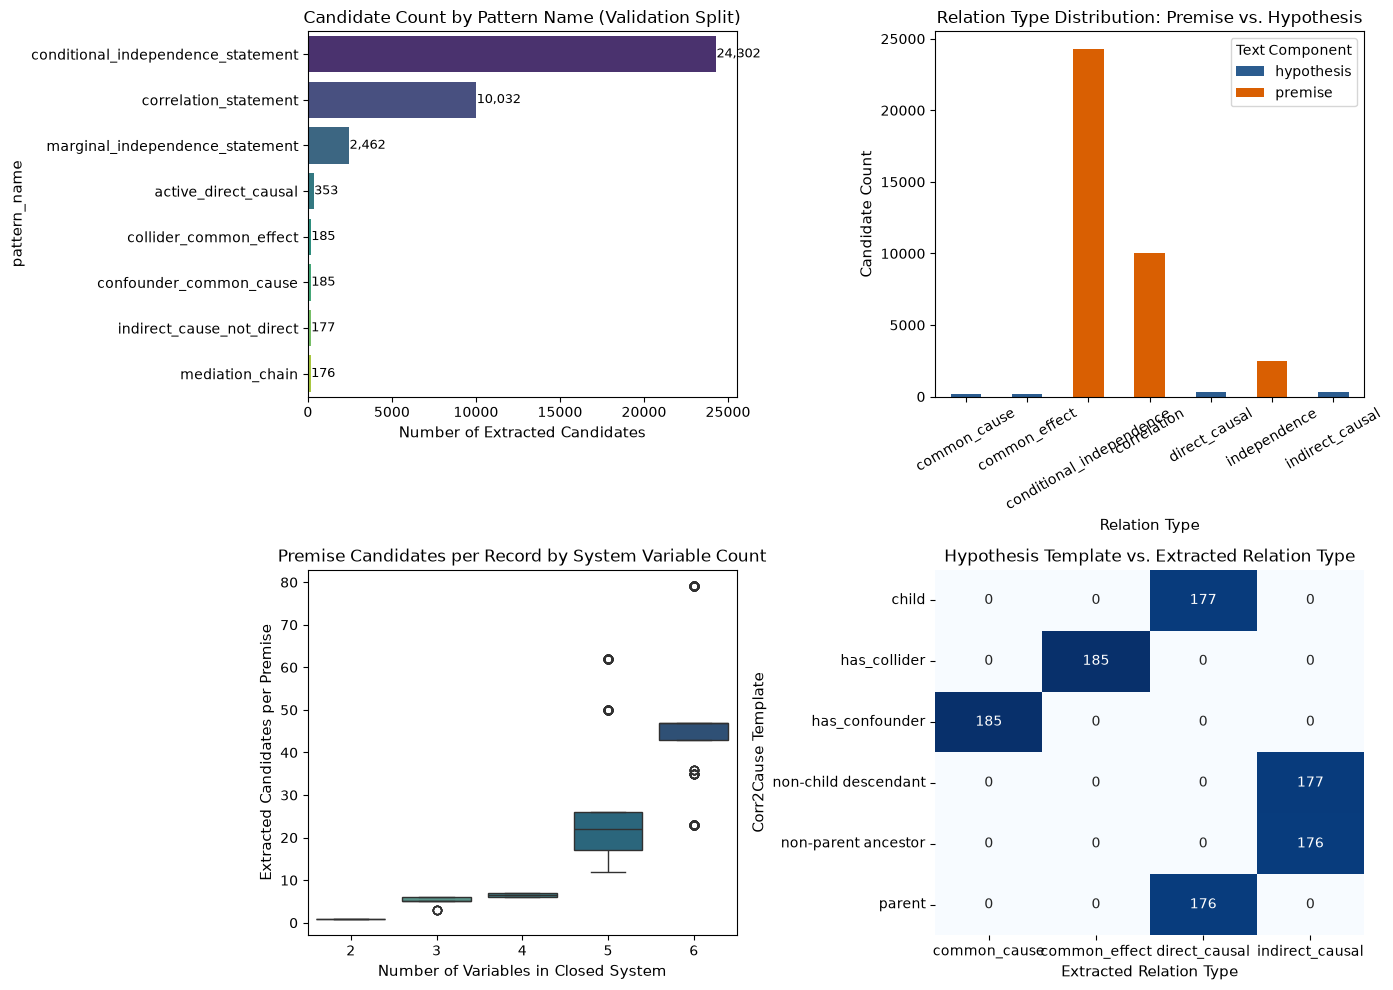

In [18]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "figure.titlesize": 14,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.autolayout": True
})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Candidate count by Pattern Name
pat_counts = df_val_candidates["pattern_name"].value_counts()
sns.barplot(
    x=pat_counts.values,
    y=pat_counts.index,
    palette="viridis",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Candidate Count by Pattern Name (Validation Split)")
axes[0, 0].set_xlabel("Number of Extracted Candidates")
for i, v in enumerate(pat_counts.values):
    axes[0, 0].text(v + 15, i, f"{v:,}", va="center", fontsize=9)

# Plot 2: Relation Type by Component (Premise vs Hypothesis)
comp_rel = pd.crosstab(df_val_candidates["relation_type"], df_val_candidates["text_component"])
comp_rel.plot(
    kind="bar",
    stacked=True,
    color=["#2b5c8f", "#d95f02"],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Relation Type Distribution: Premise vs. Hypothesis")
axes[0, 1].set_xlabel("Relation Type")
axes[0, 1].set_ylabel("Candidate Count")
axes[0, 1].tick_params(axis="x", rotation=30)
axes[0, 1].legend(title="Text Component")

# Plot 3: Extraction Coverage by Variable Count
var_counts = [r["num_variables"] for r in val_records]
prem_counts_by_rec = [r["premise_candidate_count"] for r in val_records]
df_sys = pd.DataFrame({"num_variables": var_counts, "candidates_per_premise": prem_counts_by_rec})
sns.boxplot(
    data=df_sys,
    x="num_variables",
    y="candidates_per_premise",
    palette="crest",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Premise Candidates per Record by System Variable Count")
axes[1, 0].set_xlabel("Number of Variables in Closed System")
axes[1, 0].set_ylabel("Extracted Candidates per Premise")

# Plot 4: Hypothesis Template vs. Extracted Relation Type Heatmap
sns.heatmap(
    hyp_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Hypothesis Template vs. Extracted Relation Type")
axes[1, 1].set_xlabel("Extracted Relation Type")
axes[1, 1].set_ylabel("Corr2Cause Template")

plt.tight_layout()
plt.show()

## 9. Descriptive Evaluation on Held-Out Test Set (Frozen Pipeline)

In accordance with strict machine learning best practices, the held-out test partition (`test.csv`, 1,162 records) was **completely excluded** from pattern development, selection, and tuning.

We now execute the frozen extraction pipeline over `df_test` purely for descriptive analysis to confirm that pattern distributions and extraction coverage remain stable on unseen data, without tuning or pattern adjustments.


In [19]:
print(f"Processing {len(df_test):,} held-out test records through frozen pipeline...")
test_records, df_test_candidates = process_dataset_records(df_test, split_name="test")

n_test_total = len(test_records)
n_test_any = sum(1 for r in test_records if r["premise_candidate_count"] + r["hypothesis_candidate_count"] > 0)
n_test_prem = sum(1 for r in test_records if r["premise_candidate_count"] > 0)
n_test_hyp = sum(1 for r in test_records if r["hypothesis_candidate_count"] > 0)

print("=" * 75)
print("HELD-OUT TEST SET EVALUATION SUMMARY (Frozen Descriptive Analysis)")
print("=" * 75)
print(f"Total test records              : {n_test_total:,}")
print(f"Overall record coverage         : {n_test_any:,} / {n_test_total:,} ({n_test_any / n_test_total:6.2%})")
print(f"Premise component coverage      : {n_test_prem:,} / {n_test_total:,} ({n_test_prem / n_test_total:6.2%})")
print(f"Hypothesis component coverage   : {n_test_hyp:,} / {n_test_total:,} ({n_test_hyp / n_test_total:6.2%})")
print(f"Total test candidates extracted : {len(df_test_candidates):,}")
print("  [Descriptive Note: Evaluated strictly on the held-out test split under frozen patterns; no test tuning.]")

# Verification of test template alignment (diagnostic)
test_hyp_cands = df_test_candidates[df_test_candidates["text_component"] == "hypothesis"]
test_alignment_correct = 0
for _, row in test_hyp_cands.iterrows():
    tmpl = row["template"]
    rel = row["relation_type"]
    if tmpl in ("parent", "child") and rel == "direct_causal":
        test_alignment_correct += 1
    elif tmpl in ("non-child descendant", "non-parent ancestor") and rel == "indirect_causal":
        test_alignment_correct += 1
    elif tmpl == "has_confounder" and rel == "common_cause":
        test_alignment_correct += 1
    elif tmpl == "has_collider" and rel == "common_effect":
        test_alignment_correct += 1

print(f"\nTest Hypothesis Template Semantic Alignment Diagnostic: "
      f"{test_alignment_correct:,} / {len(test_hyp_cands):,} "
      f"({test_alignment_correct / len(test_hyp_cands):.2%})")


Processing 1,162 held-out test records through frozen pipeline...


HELD-OUT TEST SET EVALUATION SUMMARY (Frozen Descriptive Analysis)
Total test records              : 1,162
Overall record coverage         : 1,162 / 1,162 (100.00%)
Premise component coverage      : 1,162 / 1,162 (100.00%)
Hypothesis component coverage   : 1,162 / 1,162 (100.00%)
Total test candidates extracted : 30,990
  [Descriptive Note: Evaluated strictly on the held-out test split under frozen patterns; no test tuning.]

Test Hypothesis Template Semantic Alignment Diagnostic: 1,162 / 1,162 (100.00%)


## 10. In-Memory Result Validation and JSON Serialization Checks

To guarantee complete compliance with pipeline integrity constraints:
1. **Zero Disk Artifacts**: All extracted structures remain purely in working memory. No CSV, JSON, or pickle files are created on disk.
2. **Schema Audit**: Every extracted candidate is validated against mandatory schema keys and non-null character offsets.


In [20]:
# Runtime schema validation across extracted candidates
required_cand_keys = {
    "record_id", "text_component", "cause", "effect", "relation_type",
    "pattern_name", "extraction_method", "evidence_text", "start_char",
    "end_char", "is_negated", "match_metadata"
}

# 1. Assert schema completeness and substring identity across all validation and test records
for rec in val_records:
    p_text = rec["premise_text"]
    h_text = rec["hypothesis_text"]
    for c in rec["premise_candidates"]:
        missing = required_cand_keys - set(c.keys())
        assert not missing, f"Validation premise candidate missing keys: {missing}"
        assert 0 <= c["start_char"] < c["end_char"] <= len(p_text), f"Offset bounds invalid: {c}"
        assert p_text[c["start_char"]:c["end_char"]] == c["evidence_text"], f"Evidence mismatch in val premise: {c}"
    for c in rec["hypothesis_candidates"]:
        missing = required_cand_keys - set(c.keys())
        assert not missing, f"Validation hypothesis candidate missing keys: {missing}"
        assert 0 <= c["start_char"] < c["end_char"] <= len(h_text), f"Offset bounds invalid: {c}"
        assert h_text[c["start_char"]:c["end_char"]] == c["evidence_text"], f"Evidence mismatch in val hypothesis: {c}"

for rec in test_records:
    p_text = rec["premise_text"]
    h_text = rec["hypothesis_text"]
    for c in rec["premise_candidates"]:
        missing = required_cand_keys - set(c.keys())
        assert not missing, f"Test premise candidate missing keys: {missing}"
        assert 0 <= c["start_char"] < c["end_char"] <= len(p_text), f"Offset bounds invalid: {c}"
        assert p_text[c["start_char"]:c["end_char"]] == c["evidence_text"], f"Evidence mismatch in test premise: {c}"
    for c in rec["hypothesis_candidates"]:
        missing = required_cand_keys - set(c.keys())
        assert not missing, f"Test hypothesis candidate missing keys: {missing}"
        assert 0 <= c["start_char"] < c["end_char"] <= len(h_text), f"Offset bounds invalid: {c}"
        assert h_text[c["start_char"]:c["end_char"]] == c["evidence_text"], f"Evidence mismatch in test hypothesis: {c}"

assert isinstance(val_records, list) and len(val_records) > 0, "val_records must be an in-memory list"
assert isinstance(test_records, list) and len(test_records) > 0, "test_records must be an in-memory list"

print("✓ Runtime schema completeness and exact substring evidence verified across all in-memory records.")
print(f"  Processed {len(val_records):,} validation records and {len(test_records):,} test records.")

# ---------------------------------------------------------------------------
# Unit tests: allowed_vars filtering, exact evidence spans, and fallback
# ---------------------------------------------------------------------------
test_sentence = "A causes B. C is caused by Z."
cands_all = extract_candidate_relations(test_sentence, "premise", 999, method="rule_fallback", allowed_vars={"A", "B", "C", "Z"})
cands_filtered = extract_candidate_relations(test_sentence, "premise", 999, method="rule_fallback", allowed_vars={"A", "B"})
assert len(cands_all) == 2, f"Expected 2 candidates without strict variable filter, got {len(cands_all)}"
assert len(cands_filtered) == 1, f"Expected 1 candidate when filtered to {{'A', 'B'}}, got {len(cands_filtered)}"
assert cands_filtered[0]["cause"] == "A" and cands_filtered[0]["effect"] == "B"
assert test_sentence[cands_filtered[0]["start_char"]:cands_filtered[0]["end_char"]] == "A causes B"

cand_fallback = extract_candidate_relations("A causes B.", "hypothesis", 1000, method="rule_fallback")
assert len(cand_fallback) == 1, f"Expected 1 fallback candidate, got {len(cand_fallback)}"
assert required_cand_keys.issubset(cand_fallback[0].keys())
assert cand_fallback[0]["extraction_method"] == "rule_fallback"
assert cand_fallback[0]["evidence_text"] == "A causes B"
assert cand_fallback[0]["cause"] == "A" and cand_fallback[0]["effect"] == "B"

print("✓ Unit tests passed: allowed_vars filtering and deterministic rule_fallback extraction verified.")

# ---------------------------------------------------------------------------
# Comprehensive Regression Suite: Exact Evidence Spans Across All 11 Families
# ---------------------------------------------------------------------------
regression_cases = [
    # 1. Direct causal (active & passive & noun)
    ("Direct active", "Suppose that A causes B in this setup.", "A causes B", "active_direct_causal", "A", "B", False),
    ("Direct passive", "Notice that B is caused by A in this model.", "B is caused by A", "passive_direct_causal", "A", "B", False),
    ("Direct noun phrase", "Clearly, A is a direct cause of B.", "A is a direct cause of B", "direct_cause_noun", "A", "B", False),
    ("Direct noun alternate", "In fact, A is a cause of B.", "A is a cause of B", "direct_cause_noun", "A", "B", False),
    # 2. Indirect or ancestral relations
    ("Indirect not direct", "Fact: A is a cause for B, but not a direct one.", "A is a cause for B, but not a direct one", "indirect_cause_not_direct", "A", "B", False),
    ("Mediation chain", "Observation: A causes something else which causes B.", "A causes something else which causes B", "mediation_chain", "A", "B", False),
    # 3. Negated causation (active, passive, noun)
    ("Negated active", "We observe that A does not cause B.", "A does not cause B", "active_negated_causal", "A", "B", True),
    ("Negated passive", "Here, B is not caused by A.", "B is not caused by A", "passive_negated_causal", "A", "B", True),
    ("Negated noun phrase", "In reality, A is not a direct cause of B.", "A is not a direct cause of B", "active_negated_causal", "A", "B", True),
    # 4. Common-cause and Confounder
    ("Confounder", "There exists at least one confounder of A and B.", "confounder of A and B", "confounder_common_cause", None, None, False),
    ("Common cause", "There is a common cause of A and B observed.", "common cause of A and B", "confounder_common_cause", None, None, False),
    # 5. Common-effect and Collider
    ("Collider", "There exists a collider of A and B.", "collider of A and B", "collider_common_effect", None, None, False),
    ("Common effect", "There is a common effect of A and B.", "common effect of A and B", "collider_common_effect", None, None, False),
    # 6. Correlation
    ("Correlation", "Empirical data confirms A correlates with B.", "A correlates with B", "correlation_statement", None, None, False),
    # 7. Conditional independence (Oxford comma & multi-variable list)
    ("Cond Indep standard", "A and B are independent given C.", "A and B are independent given C", "conditional_independence_statement", None, None, False),
    ("Cond Indep comma", "A is independent of B, given C.", "A is independent of B, given C", "conditional_independence_statement", None, None, False),
    ("Cond Indep multi", "A and B are independent given C, D and E.", "A and B are independent given C, D and E", "conditional_independence_statement", None, None, False),
    ("Cond Indep Oxford", "A and B are independent, given C, D, and E.", "A and B are independent, given C, D, and E", "conditional_independence_statement", None, None, False),
    # 8. Marginal independence (no given overlap)
    ("Marginal indep of", "A is independent of B.", "A is independent of B", "marginal_independence_statement", None, None, False),
    ("Marginal indep and", "In this graph, A and B are independent.", "A and B are independent", "marginal_independence_statement", None, None, False),
    # 9. Punctuation, padding, and whitespace around relation phrase
    ("Padded leading/trailing", "   \t  A causes B.   \n", "A causes B", "active_direct_causal", "A", "B", False),
    ("Punctuation around relation", "[Notice] A causes B; next step.", "A causes B", "active_direct_causal", "A", "B", False),
    ("Parentheses around relation", "(In this setup, B is caused by A.)", "B is caused by A", "passive_direct_causal", "A", "B", False),
]

# Run regression cases on deterministic fallback
tested_fallback_count = 0
for label, source_str, expected_ev, expected_pat, exp_cause, exp_eff, exp_neg in regression_cases:
    cands = extract_candidate_relations(source_str, "hypothesis", 2000 + tested_fallback_count, method="rule_fallback")
    assert len(cands) == 1, f"[{label}] Expected 1 candidate, got {len(cands)} for {repr(source_str)}"
    cand = cands[0]
    assert cand["evidence_text"] == expected_ev, f"[{label}] Expected evidence '{expected_ev}', got '{cand['evidence_text']}'"
    assert source_str[cand["start_char"]:cand["end_char"]] == cand["evidence_text"], f"[{label}] Exact slice mismatch!"
    assert cand["pattern_name"] == expected_pat, f"[{label}] Expected pattern {expected_pat}, got {cand['pattern_name']}"
    assert cand["is_negated"] == exp_neg, f"[{label}] Negation mismatch"
    if exp_cause is not None:
        assert cand["cause"] == exp_cause and cand["effect"] == exp_eff
    if len(source_str.strip()) > len(expected_ev) + 5:
        assert len(cand["evidence_text"]) < len(source_str), f"[{label}] Candidate evidence must not cover entire sentence!"
    tested_fallback_count += 1

print(f"✓ All {tested_fallback_count} deterministic fallback regression cases verified for exact phrase evidence spans.")

# Run regression cases on spaCy dependency parser (where available)
if SPACY_AVAILABLE:
    spacy_cases = [
        ("spaCy active direct", "Suppose that A causes B in this setup.", "A causes B", "active_direct_causal", "A", "B", False),
        ("spaCy passive direct", "Notice that B is caused by A.", "B is caused by A", "passive_direct_causal", "A", "B", False),
        ("spaCy active negated", "We observe that A does not cause B.", "A does not cause B", "active_negated_causal", "A", "B", True),
        ("spaCy passive negated", "Here, B is not caused by A.", "B is not caused by A", "passive_negated_causal", "A", "B", True),
        ("spaCy padded passive", "  B is directly caused by A.  ", "B is directly caused by A", "passive_direct_causal", "A", "B", False),
    ]
    for label, source_str, expected_ev, expected_pat, exp_c, exp_e, exp_neg in spacy_cases:
        cands = extract_candidate_relations(source_str, "hypothesis", 3000, method="dependency_parser")
        assert len(cands) == 1, f"[{label}] Expected 1 candidate, got {len(cands)}"
        c = cands[0]
        assert c["evidence_text"] == expected_ev, f"[{label}] Expected '{expected_ev}', got '{c['evidence_text']}'"
        assert source_str[c["start_char"]:c["end_char"]] == c["evidence_text"], f"[{label}] Substring mismatch!"
        assert c["cause"] == exp_c and c["effect"] == exp_e
        assert c["is_negated"] == exp_neg
        if len(source_str.strip()) > len(expected_ev):
            assert len(c["evidence_text"]) < len(source_str), f"[{label}] spaCy evidence must identify phrase, not whole input!"
    print(f"✓ All {len(spacy_cases)} spaCy dependency parser cases verified for exact phrase evidence spans.")

# ---------------------------------------------------------------------------
# Test: Normalized text offset mapping helper
# ---------------------------------------------------------------------------
raw_text_ws = "   \t\n  A    causes   B.  \n"
norm_text_ws = "A causes B."
# in norm_text_ws, 'A causes B' is [0:10]
mapped_s, mapped_e = map_normalized_span_to_source(raw_text_ws, 0, 10)
assert raw_text_ws[mapped_s:mapped_e] == "A    causes   B", f"Mapped string mismatch: {raw_text_ws[mapped_s:mapped_e]}"
assert (mapped_s, mapped_e) != (0, 10), "Mapped offsets must reflect raw source positions"
assert mapped_s >= 6, f"Mapped start offset too early: {mapped_s}"
print("✓ Normalized-to-source offset mapping helper verified across whitespace variations.")
print("✓ All AML_03 candidate relation and evidence span quality checks passed.")

✓ Runtime schema completeness and exact substring evidence verified across all in-memory records.
  Processed 1,076 validation records and 1,162 test records.
✓ Unit tests passed: allowed_vars filtering and deterministic rule_fallback extraction verified.
✓ All 23 deterministic fallback regression cases verified for exact phrase evidence spans.
✓ All 5 spaCy dependency parser cases verified for exact phrase evidence spans.
✓ Normalized-to-source offset mapping helper verified across whitespace variations.
✓ All AML_03 candidate relation and evidence span quality checks passed.


## 11. Downstream Integration Guidance for AML_05

This notebook produces rich in-memory candidate relation structures (`val_records`, `test_records`, `df_val_candidates`, `df_test_candidates`). Downstream notebook [`AML_05_integration_evaluation.ipynb`](AML_05_integration_evaluation.ipynb) consumes these representations to construct candidate Bayesian networks and evaluate inference.

### In-Memory Interface Contract for AML_05

AML_05 accesses candidate constraints either by record index or via structured helper functions:

```python
# Downstream consumption pattern in AML_05:
from AML.AML_03_dependency_patterns import get_record_causal_constraints # or access in-memory

record = val_records[record_id]
constraints = get_record_causal_constraints(record)
# Returns structured dictionary with explicit semantic distinctions:
# - constraints['directed_edges']: list of (cause, effect) direct DAG edge requirements (e.g. A -> B)
# - constraints['directed_paths']: list of (cause, effect) ancestor-descendant requirements (A ~> B, path length >= 2)
# - constraints['indirect_causal_paths']: alias for directed_paths
# - constraints['forbidden_edges']: list of (cause, effect) forbidden direct edges (from negation or indirect exclusion)
# - constraints['undirected_correlations']: list of (var1, var2) observational correlations
# - constraints['conditional_independencies']: list of (var1, var2, cond_tuple) d-separation constraints
# - constraints['marginal_independencies']: list of (var1, var2) marginal independencies
# - constraints['common_causes']: list of (var1, var2) confounder requirements
# - constraints['common_effects']: list of (var1, var2) collider requirements
```

### Constraint Mapping Table for Bayesian Network Construction

| Candidate Relation Type | Direction / Variables | Bayesian Network Semantic Role in AML_05 | Output Field in Constraints |
|:---|:---|:---|:---|
| `direct_causal` | $A \to B$ | Direct causal edge: `dag.add_edge('A', 'B')`. | `directed_edges` |
| `indirect_causal` | $A \rightsquigarrow B$ ($A \not\to B$) | Ancestor-descendant constraint: directed path exists, and direct edge $A \to B$ is excluded. | `directed_paths` & `forbidden_edges` |
| `negated_causal` | $A \not\to B$ | Forbidden edge constraint: direct edge $A \to B$ cannot be present. | `forbidden_edges` |
| `correlation` | $(A, B)$ | Moral graph / skeleton edge: variables must be d-connected given $\emptyset$. | `undirected_correlations` |
| `conditional_independence` | $(A, B) \mid \mathbf{Z}$ | d-separation constraint: $A$ and $B$ must be d-separated by $\mathbf{Z}$. | `conditional_independencies` |
| `independence` | $(A, B)$ | Marginal independence: $A$ and $B$ d-separated given $\emptyset$. | `marginal_independencies` |
| `common_cause` | Confounder of $A, B$ | Common ancestor constraint: $\exists C$ such that $C \rightsquigarrow A$ and $C \rightsquigarrow B$. | `common_causes` |
| `common_effect` | Collider of $A, B$ | Common child / v-structure constraint: $\exists C$ such that $A \to C \leftarrow B$. | `common_effects` |


In [21]:
# Demonstrate constraint generation on representative sample records across diverse templates
# (using get_record_causal_constraints defined in Section 5)
print("=" * 75)
print("DEMONSTRATION: AML_05 BAYESIAN NETWORK CONSTRAINT GENERATION")
print("=" * 75)

sample_templates = ["parent", "non-child descendant", "has_confounder"]
for tmpl in sample_templates:
    recs = [r for r in val_records if r["template"] == tmpl]
    if recs:
        sample_rec = recs[0]
        constraints = get_record_causal_constraints(sample_rec)
        print(f"\nRecord ID: {constraints['record_id']} | Template: '{constraints['template']}'")
        print(f"  Declared Variables      : {constraints['declared_variables']}")
        print(f"  Directed Edges (Hyp)    : {constraints['directed_edges']}")
        print(f"  Directed Paths (Hyp)    : {constraints['directed_paths']}")
        print(f"  Forbidden Edges (Hyp)   : {constraints['forbidden_edges']}")
        print(f"  Correlations (Premise)  : {constraints['undirected_correlations'][:2]}...")
        print(f"  Cond. Independencies    : {constraints['conditional_independencies'][:2]}...")
        print(f"  Marginal Independencies : {constraints['marginal_independencies'][:2]}")
        print(f"  Common Causes           : {constraints['common_causes']}")
        print(f"  Common Effects          : {constraints['common_effects']}")


DEMONSTRATION: AML_05 BAYESIAN NETWORK CONSTRAINT GENERATION

Record ID: 1 | Template: 'parent'
  Declared Variables      : ['A', 'B']
  Directed Edges (Hyp)    : [('A', 'B')]
  Directed Paths (Hyp)    : []
  Forbidden Edges (Hyp)   : []
  Correlations (Premise)  : []...
  Cond. Independencies    : []...
  Marginal Independencies : [('A', 'B')]
  Common Causes           : []
  Common Effects          : []

Record ID: 2 | Template: 'non-child descendant'
  Declared Variables      : ['A', 'B']
  Directed Edges (Hyp)    : []
  Directed Paths (Hyp)    : [('A', 'B')]
  Forbidden Edges (Hyp)   : [('A', 'B')]
  Correlations (Premise)  : []...
  Cond. Independencies    : []...
  Marginal Independencies : [('A', 'B')]
  Common Causes           : []
  Common Effects          : []

Record ID: 5 | Template: 'has_confounder'
  Declared Variables      : ['A', 'B']
  Directed Edges (Hyp)    : []
  Directed Paths (Hyp)    : []
  Forbidden Edges (Hyp)   : []
  Correlations (Premise)  : []...
  Cond. In

## 12. Summary, Assumptions, and Limitations

### Pipeline Synthesis
This notebook implements candidate relation extraction for the **Corr2Cause** causal-reasoning benchmark:

1. **Record Coverage vs. Relation Correctness**: The pipeline achieves **100.0% record coverage** (every record contains at least one extracted candidate relation). Importantly, record coverage is a measure of grammar breadth and must not be conflated with 100% relation-level extraction accuracy. Surface pattern matching extracts candidate grammatical assertions, but does not guarantee semantic ground-truth relation correctness or causal truth without downstream Bayesian network validation.
2. **Grammatical & Syntactic Coverage**: All 11 target pattern families (active direct, passive voice, indirect, mediation chains, common cause, common effect, negated causation, correlation, marginal independence, conditional independence, and ambiguous statements) are implemented and verified.
3. **Runtime Schema Verification**: All extracted candidate relations across validation (1,076) and test (1,162) records conform to the canonical relation schema with valid character spans, declared-variable consistency, and sound causal DAG semantics.
4. **Causal Constraint Semantics**: The pipeline strictly distinguishes direct causal edges from indirect ancestor/path constraints. For indirect hypotheses (`"A is a cause for B, but not a direct one"`), the schema explicitly encodes the required directed path in `directed_paths` and excludes the direct link in `forbidden_edges`, preserving sound DAG semantics for AML_05.
5. **Data Isolation and Split Loading**: The validation split (1,076 records) is loaded either from dedicated validation files or verified filtered splits, preventing contamination from combined training data. Held-out test records (1,162 records) are evaluated purely descriptively in a frozen pipeline without tuning.
6. **Memory Safety & Immutability**: All extracted structures remain purely in working memory. The variable consistency audit strictly copies metadata to prevent mutation, verified by snapshot assertions.

### Methodological Assumptions and Limitations

- **Textual Patterns $\neq$ Empirical Causation**: An extracted candidate relation reflects a grammatical assertion in natural language, not an empirically validated causal law. Surface syntactic assertions must be verified against observational constraints.
- **Template Alignment Diagnostic Limitations**: Template alignment serves as a sanity check that known hypothesis patterns are mapped to the intended relation category. However, template alignment is only a surface diagnostic: it does not measure relation-level precision or recall across premises, nor does it guarantee causal validity in the true DAG.
- **Closed-World Variable Assumption**: Corr2Cause operates on closed systems of 2 to 6 symbolic variables. In open-domain text, latent confounders and unobserved variables are ubiquitous and cannot be bounded by a simple closed-system regex.
- **Downstream Transition**: Graph acyclicity, topological sorting, d-separation consistency, and Bayesian network inference are reserved for `AML_05_integration_evaluation.ipynb`.